# Pricing Asian Options and the Monte Carlo method

In [14]:
# Imports
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as Line2D
from math import erf
from typing import Tuple

# Define colors for plotting
BLUE = '#1f77b4'
RED = '#d62728'
GRAY = '#808080'
GREEN = '#2ca02c'
AMBER = '#ffc107'

## Pricing Asian Options

**Asian option**: a path-dependent option whose payoff depends on the average price of the underlying asset over time.


- Average price: arithmetic or geometric
- Exercise is usually European style

- Advantages:
    - smooths volatile market movements
    - excellent hedging tool when the market participants are exposed to average prices - popular in commodity markets


- Example of an Asian option:
    - Call option on
    - a WTI (West Texas international, oil underlying) contract
    - with 1000 bbl (barrel) notional,
    - option excercise date 2025 January 31,
    - 2025 February 5 delivery,
    - strike 85 \$/bbl.
    - The option is based on the daily average prices in 2025 January.

- Pricing methods:
    - exact calculation: not always possible or extremely computing intensive
    - Monte Carlo simulation
    - numerical solution of the pricing PDE
    - **moment matching** - most popular
    - upper/lower price bounds
    - transformations (Laplace)


<h3><center> Mathematical notations </center></h3>

- $(S_t)_{t\in [0,T]}$: asset price process
- $S_0$: initial price
- $T$: exercise date
- $K$: strike
- $\{ t_1,\ldots,t_n \}$: fix observation times, $0\leq t_1 \leq \ldots \leq t_n \leq T$ on which we take the average of the asset price
- $A_T$: average of the underlying asset prices in time interval $[0,T]$
- $x_+=max(x,0)$: positive value of $x$

<h3><center> Types of Asian options </center></h3>

- Call or Put
- Strike style
    - **Fixed strike**: Payoff of call option$=(A_T-K)_+$
    - Floating strike: Payoff of call option$=(S_T - A_T)_+$



- Averaging type and Monitoring frequency

**Averaging type $\quad$  Continuously monitored $\qquad \qquad \ $ Discretely monitored**
Geometric    $\qquad$    $\left(exp\left\{ \frac{1}{T}\int\limits_0^T \log S_t \,dt \right\} -K \right)_+$    $\quad$      $\left(  \left( \prod\limits_{i=1}^n S_{t_i} \right)^{1/n} -K \right)_+ $

Arithmetic  $\qquad \qquad$  $\left( \frac{1}{T}\int\limits_0^T S_t\, dt-K \right)_+$ $\qquad \qquad \quad$ $\color{blue}{\left( \frac{1}{n} \sum\limits_{i=1}^n S_{t_i} -K \right)_+} $



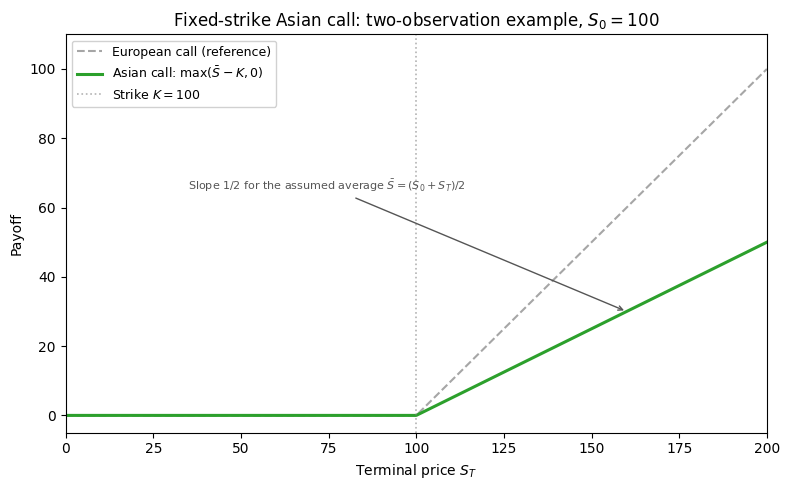

In [8]:
# Parameters
K = 100
S0 = 100
S = np.linspace(0, 200, 1000)

# Illustrative averaging rule: observe only S0 and S_T, with equal weights.
# A general Asian option needs the whole set of observed prices.
S_avg = (S0 + S) / 2
asian_payoff = np.maximum(S_avg - K, 0)
call_payoff = np.maximum(S - K, 0)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(S, call_payoff, color='#808080', lw=1.5, ls='--', alpha=0.7,
        label='European call (reference)')
ax.plot(S, asian_payoff, color='#2ca02c', lw=2.2,
        label=r'Asian call: $\max(\bar{S} - K, 0)$')
ax.axvline(K, color='#808080', lw=1.2, ls=':', alpha=0.6,
           label=f'Strike $K={K}$')
ax.set_title(r'Fixed-strike Asian call: two-observation example, $S_0=100$')
ax.set_xlabel(r'Terminal price $S_T$')
ax.set_ylabel('Payoff')
ax.set_xlim(0, 200)
ax.set_ylim(-5, 110)
ax.legend(fontsize=9, framealpha=0.9)
ax.annotate(
    r'Slope 1/2 for the assumed average $\bar{S}=(S_0+S_T)/2$',
    xy=(160, max((S0 + 160) / 2 - K, 0)),
    xytext=(35, 65),
    arrowprops=dict(arrowstyle='->', color='#555', lw=1),
    fontsize=8, color='#555'
)
fig.tight_layout()
plt.show()

<h3><center> Pricing of Asian options </center></h3>

- Price (PV) of a Call Asian option at time $t=0: \quad e^{-rT}E_*\left[ (A_T-K)_+ \right]$
- There is no closed formula for the price, as $A_T$ is the arithmetical average of lognormal random variables, which is (usually) not lognormally distributed


- Why is it so hard to calculate?

- Because we have to calculate a multiple integral with $n$ variables which is the following in case $S_t$ is the GBM process with parameters $\mu$ and $\nu$:

$E_*\left[ (A_T-K)_+ \right] =  $

$\ =\scriptsize \int\limits_{-\infty}^{\infty}\cdots \int\limits_{-\infty}^{\infty}
\left[ \frac{S_0}{n}
\left( e^{\left(\mu- \frac{\nu^2}{2} \right)t_1+\nu x_1}+\ldots+e^{\left(\mu- \frac{\nu^2}{2} \right)t_n+\nu x_n} \right)
-K \right]_+ f_{(W_{t_1},\ldots,W_{t_n})}(x_1,\ldots,x_n)dx_1\ldots dx_n$

<h3><center> Pricing by moment matching </center></h3>

- First proposed by Edmond Levy for Asian options
- Let us assume that $S_t$ is the GBM process, i.e. $\frac{S_t}{S_0}$ is lognormally distributed
- We approximate $A_T$ by a properly scaled and parametrized lognormal random variable $U$
- The lognormal distribution is determined by its first two moments, therefore we match the first two moments of $A_T$ and $U$


First and second moments of $A_T$ are
- $ E \left(A_T \right) =  \frac{S_0}{n}\sum\limits_{i=1}^{n}\exp\left\{rt_i\right\}$
- $ E \left( A_T^2 \right) =  \frac{S^2_0}{n^2}\sum\limits_{i,j=1}^{n}\exp\left\{r(t_i+t_j) + \sigma^2\min(t_i, t_j)\right\}$

$\hspace{-5mm}$
If $\frac{U}{S_0}$ is lognormal with parameters $m$ and $\sigma$, then the first two moments of $U$ are

$\quad EU = S_0\exp\left\{m+\frac{\sigma^2}{2} \right\} \quad $ and
$\quad E U^2 = S_0^2 \exp\left\{2m+2\sigma^2 \right\}$

Matching the first two moments and solving the system of equations:
- $m = 2\, \text{log} \left( \frac{E\left(A_T\right)}{S_0} \right)- \frac{1}{2} \, \text{log} \left( \frac{E\left(A_T^2\right)}{S_0^2} \right)$
- $\sigma^2 = \text{log} \left( \frac{E\left(A_T^2\right)}{S_0^2} \right) - 2 \text{log} \left( \frac{E\left(A_T\right)}{S_0} \right)$

Finally we can approximate the PV of the Call Asian option at time $t=0$:

$e^{-rT}E_*\left[ (A_T-K)_+ \right] \approx$
$e^{-rT}E_*\left[ (U-K)_+\right] = e^{-rT}E_*\left[ (S_0e^{m+\sigma N(0,1^2)}-K)_+\right]$


The calculation leads to a very similar integral which we calculated when deriving the Black-Scholes formula:

$E_*\left[ (U-K)_+\right] = \int\limits_{-\infty}^{\infty} (S_0e^{m+\sigma x}-K)_+ \cdot \frac{1}{\sqrt{2\pi}}e^{-x^2/2}\, dx$

$= S_0 \int\limits_{\frac{1}{\sigma}\left[ log\left( \frac{K}{S_0}\right)-m\right]}^{\infty} e^{m+\sigma x} \frac{1}{\sqrt{2\pi}}e^{-x^2/2}\, dx \quad + \quad
K  \int\limits_{\frac{1}{\sigma}\left[ log\left( \frac{K}{S_0}\right)-m\right]}^{\infty}  \frac{1}{\sqrt{2\pi}}e^{-x^2/2}\, dx$




To calculate the first integral, the key idea is to observe that the integrand is the density function of $N(\sigma, 1^2)$:

$e^{m+\sigma x} \frac{1}{\sqrt{2\pi}}e^{-x^2/2} = e^{m+\sigma^2/2}\cdot \frac{1}{\sqrt{2\pi}} e^{-\frac{1}{2}(x-\sigma)^2}$


$E_*\left[ (U-K)_+\right] = S_0 e^{m+\sigma x}P\left(N(\sigma,1^2)>\frac{1}{\sigma}\left[ log\left( \frac{K}{S_0}\right)-m\right]\right) + $

$\qquad \qquad \qquad + P\left(N(0,1^2)> \frac{1}{\sigma}\left[ log\left( \frac{K}{S_0}\right)-m\right] \right)$

Finishing off the calculations, we get the moment matching approximation price of a Call Asian option:

$\hspace{30mm} e^{-rT}\left(S_0 e^{m+\frac{\sigma^2}{2}} \Phi\left(d_1\right)-K \Phi\left(d_2\right)\right)$, where

- $d_1=\frac{\log \left(\frac{S_0}{K}\right)+m+\sigma^2}{\sigma}$
- $d_2=d_1-\sigma$


When do we consider the price derived by the moment matching approximation appropriate?

If the moment matching price $P_{MM}$ lies within the $95\%$ confidence interval of the Monte Carlo simulation price $P_{MC}$:

$P_{MM} \in \left[ P_{MC}-1.96\cdot sd(P_{MC}), P_{MC}+1.96\cdot sd(P_{MC}) \right]$

or equivalently, for the standardized difference

$\frac{P_{MM}-P_{MC}}{sd(P_{MC})} \in \left[ -1.96, +1.96 \right]$

## Monte Carlo method

### Monte Carlo simulation

Monte Carlo methods approximate quantities using **random sampling**.
Instead of solving a problem analytically, we simulate many random outcomes and compute averages.
The basic idea is:

\begin{equation}
\mathbb{E}[X] \approx \frac{1}{N}\sum_{i=1}^{N} X_i
\end{equation}

where $X_i$ are independent simulated sampled.

### Example: Coin Toss
Suppose we toss a fair coin. The probability of heads is $P(\text{heads})=0.5$. We can estimate this probability using Monte Carlo simulation by repeatedly tossing the coin and computing the sample mean.
As the number of tosses increases, the estimate converges to the true probability due to the **Law of Large Numbers**.

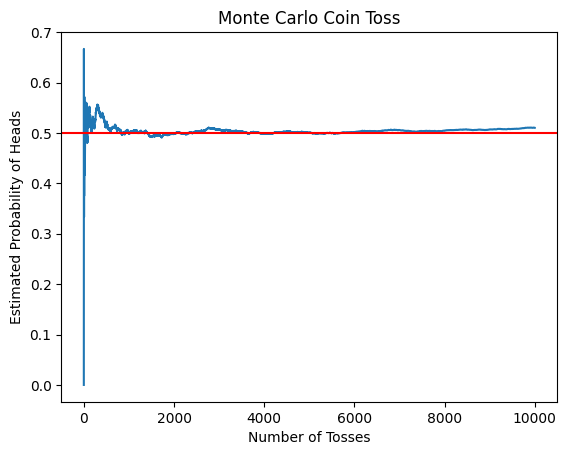

In [10]:
N=10000

coins=np.random.randint(0,2,N)

running_mean=np.cumsum(coins)/np.arange(1,N+1)

plt.plot(running_mean)
plt.axhline(0.5,color="red")
plt.title("Monte Carlo Coin Toss")
plt.xlabel("Number of Tosses")
plt.ylabel("Estimated Probability of Heads")
plt.show()

### Example: Approximating $\pi$
Consider a unit circle inside a square.

If we sample points uniformly in the square, the probability that a point lies inside the circle is

\begin{equation}
\frac{\text{Area of circle}}{\text{Area of square}} = \frac{\pi}{4}
\end{equation}

Therefore

\begin{equation}
\pi \approx 4 \times \frac{\text{points inside circle}}{\text{total points}}
\end{equation}

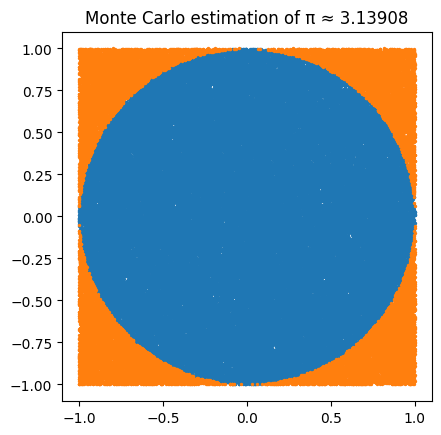

In [11]:
N=100000

x=np.random.uniform(-1,1,N)
y=np.random.uniform(-1,1,N)

inside=x**2+y**2<=1

pi_est=4*np.mean(inside)

plt.scatter(x[inside],y[inside],s=2)
plt.scatter(x[~inside],y[~inside],s=2)
plt.title(f"Monte Carlo estimation of π ≈ {pi_est}")
plt.gca().set_aspect("equal")
plt.show()

## Monte Carlo method in pricing

### Why Monte Carlo methods in option pricing?

In risk-neutral pricing, the value of a derivative is given by the discounted expectation of its payoff:
\begin{equation}
V_0 = e^{-rT}\mathbb{E}[\text{Payoff}].
\end{equation}

There are several approaches to computing this expectation.

For some simple contracts, **analytic formulas** exist. A well-known example is the Black-Scholes formula for European call and put options. Analytic formulas are extremely fast and accurate, but they are only available for a limited set of payoff structures and model assumptions.

Another common approach is to formulate the pricing problem as a **partial differential equation (PDE)**. Under the Black-Scholes model, for example, the price $V(S,t)$ of a European option satisfies the Black-Scholes PDE. Numerical PDE methods can be very effective for problems involving one or two underlying variables.

However, these approaches become difficult to apply in many realistic situations.

First, many derivatives have **path-dependent payoffs**, meaning that the payoff depends on the entire trajectory of the asset price rather than only the terminal value. Examples include Asian options and barrier options.

Second, many financial products depend on **multiple underlying assets**. In such cases the corresponding PDE becomes high-dimensional, and numerical PDE methods suffer from the **curse of dimensionality**, meaning that the computational cost grows exponentially with the number of dimensions.

Monte Carlo simulation avoids these difficulties. Instead of solving a PDE or deriving an analytic formula, it directly approximates the risk-neutral expectation
\begin{equation}
V_0 \approx e^{-rT}\frac{1}{N}\sum_{i=1}^{N}\text{Payoff}^{(i)},
\end{equation}
where each payoff is generated from a simulated price path.

For this reason, Monte Carlo methods are widely used in practice for pricing complex, path-dependent, or high-dimensional derivatives.

### Estimating the expected payoff

We will work in the Black-Scholes model where the underlying follows

$$ dS_t = rS_tdt + \sigma S_tdW_t $$

Law of large numbers: Expected value can be estimated with the sample mean

$$ m = E[X] \approx \frac{1}{N}\sum_iX_i $$



$$ V(t) = e^{-r(T-t)}\mathbb{E}[Payoff(S_T)] $$

* Generate n independent samples from $S_T$
* Evaluate the payoff function on the samples and take mean

We implement payoff function for each contract so the second step is easy, the complication arise at the first step.

In the general case we dont know the distribution of $S_T$, we only know it's inital value at some time $t$ and we have an assumption on it's dynamic (our market model). How to obtain samples from $S_T$?

### Euler–Maruyama method

Consider the following stochastic differential equation:

$$ dS_t = \mu(t, S_t) dt + \sigma(t,S_t)dW_t $$

One can approximate the solution numerically

* partition the time interval of $[0,T]$ into $N$ subintervals: $\Delta T = T/N$,   $ \quad t_i = i*\Delta T$
* we know the stock price today $S_0$. We approximate the stock price at the next timepoint:
$$ S_{t_{i+1}} = S_{t_i} + \mu(t_i, S_{t_i}) \Delta T + \sigma(t_i,S_{t_i}) \cdot (W_{t_{i+1}} - W_{t_i}) $$
* $W_t$ is a Brownian motion, it's increments are independent normals:
$$ W_{t_{i+1}} - W_{t_i} \sim \mathcal{N}(0,t_{i+1}-t_i) $$
$$ W_{t_{i+1}} - W_{t_i} = \sqrt{\Delta T}\epsilon_i, \quad \epsilon_i\sim \mathcal{N}(0,1)$$

### Milstein method

Milstein method improves the accuracy of the Euler method by adding a correction term.

$$
S_{t_{i+1}} =
S_{t_i} + \underbrace{\mu(t_i, S_{t_i}) \Delta T + \sigma(t_i,S_{t_i}) \cdot (W_{t_{i+1}} - W_{t_i}) }_{\text{Euler step}}
+\underbrace{\frac{1}{2}(\frac{\partial}{\partial S}\sigma(t_i,S_{t_i})) \sigma(t_i,S_{t_i}) ((W_{t_{i+1}} - W_{t_i})^2-\Delta T)}_{\text{correction}} $$

It requires the derivative of the diffusion term. the correction term vanishes when $\sigma(t,S_t)$ does not depend on the spot and Milstein method become identical to Euler.

Euler: weak convergence order of 1, strong convergence order of 1/2

Milstein: weak convergence order of 1, strong convergence order of 1



### Solution to the SDE in the BS model

In BS model the risky asset follows GBM:

$$ dS_t = rS_t dt + \sigma S_tdW_t $$

For this relatively simple SDE the exact solution is known:

$$ S_t = S_0 e^{(r-\frac{\sigma^2}{2})t+\sigma W_t} $$

If we only need samples from $S_T$ we can simulate it directly, no need for partitioning the time interval and simulate the stock price for (from the contract's point of view) useless time points!

### Random number generation

We will use pseudo random numbers: The generated numbers will be statistically random, but if we fix a seed, always the same numbers will be generated

How many random numbers will be needed?

* For a single path, we will need as many $\epsilon$ as the number of simulation tenors.

* Therefore the total number of $\epsilon$ needed is <b>NumberOfPaths * NumberOfSimulTenors<b>

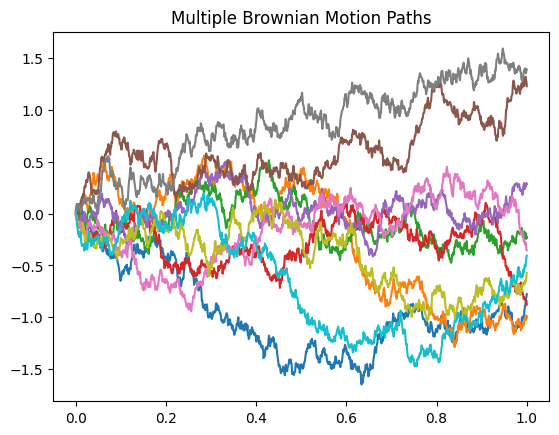

In [12]:
T=1
N=1000
dt=T/N

dW=np.sqrt(dt)*np.random.randn(N)
W=np.cumsum(dW)

t=np.linspace(0,T,N)

for _ in range(10):
    dW=np.sqrt(dt)*np.random.randn(N)
    W=np.cumsum(dW)
    plt.plot(t,W)

plt.title("Multiple Brownian Motion Paths")
plt.show()

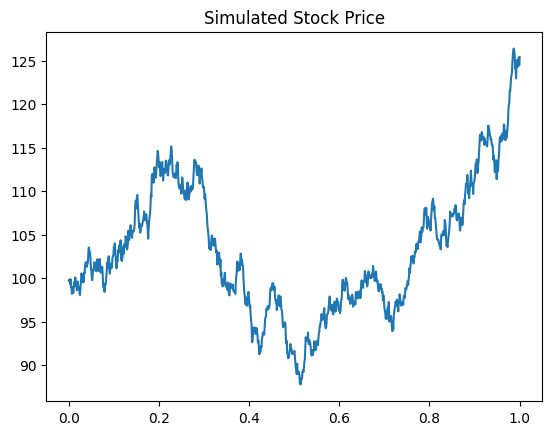

In [13]:
S0=100
r=0.05
sigma=0.2

W=np.cumsum(np.sqrt(dt)*np.random.randn(N))

S=S0*np.exp((r-0.5*sigma**2)*t+sigma*W)

plt.plot(t,S)
plt.title("Simulated Stock Price")
plt.show()

### Pricing forwards and European puts with MC

In [15]:
r = 0.05
sigma = 0.20
T = 1.0

In [16]:
N = lambda x: 0.5 * (1 + erf(x / np.sqrt(2)))

def ci(x: np.ndarray) -> Tuple[float, float, float]:
    m = np.mean(x)
    s = np.std(x, ddof=1)
    w = 1.96 * s / np.sqrt(len(x))
    return m, m - w, m + w

In [17]:
def forward_bs(S0: float, K: float, r: float, T: float) -> float:
    return S0 - K * np.exp(-r*T)

def put_bs(S0: float, K: float, r: float, sigma: float, T: float) -> float:
    d1 = (np.log(S0/K) + (r + 0.5*sigma**2)*T) / (sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)
    return K*np.exp(-r*T)*N(-d2) - S0*N(-d1)

In [18]:
def mc_terminal(S0: float, r: float, sigma: float, T: float, n: int, seed: int = 1) -> np.ndarray:
    rng = np.random.default_rng(seed)
    Z = rng.standard_normal(n)
    return S0 * np.exp((r - 0.5*sigma**2)*T + sigma*np.sqrt(T)*Z)

def mc_put(S0: float, K: float, r: float, sigma: float, T: float, n: int, seed: int = 1) -> Tuple[float, float, float, np.ndarray, np.ndarray]:
    ST = mc_terminal(S0, r, sigma, T, n, seed)
    X = np.exp(-r*T) * np.maximum(K - ST, 0)
    return (*ci(X), ST, X)

def mc_forward(S0: float, K: float, r: float, sigma: float, T: float, n: int, seed: int = 1) -> Tuple[float, float, float, np.ndarray, np.ndarray]:
    ST = mc_terminal(S0, r, sigma, T, n, seed)
    X = np.exp(-r*T) * (ST - K)
    return (*ci(X), ST, X)

In [19]:
fwd_an = forward_bs(S0, K, r, T)
put_an = put_bs(S0, K, r, sigma, T)

fwd_mc, fwd_lo, fwd_hi, ST_fwd, X_fwd = mc_forward(S0, K, r, sigma, T, 1000000)
put_mc, put_lo, put_hi, ST_put, X_put = mc_put(S0, K, r, sigma, T, 1000000)

print(f"Forward analytic: {fwd_an:.4f}")
print(f"Forward MC:       {fwd_mc:.4f}  [{fwd_lo:.4f}, {fwd_hi:.4f}]")
print(f"Put analytic:     {put_an:.4f}")
print(f"Put MC:           {put_mc:.4f}  [{put_lo:.4f}, {put_hi:.4f}]")

Forward analytic: 4.8771
Forward MC:       4.8668  [4.8273, 4.9063]
Put analytic:     5.5735
Put MC:           5.5608  [5.5439, 5.5778]


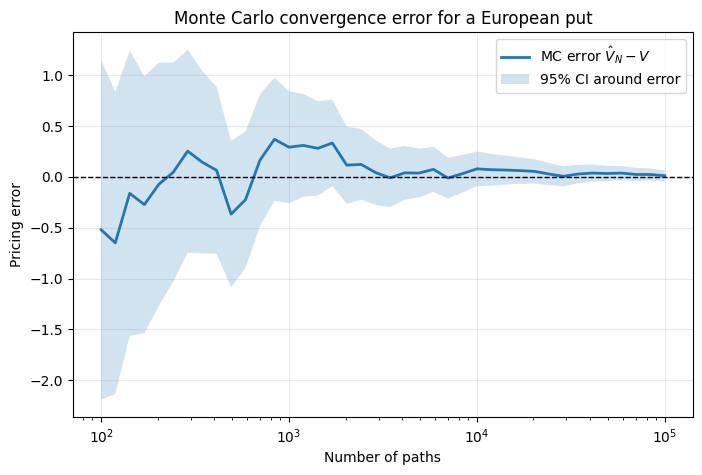

In [20]:
path_grid = np.unique(np.logspace(2, 5, 40, dtype=int))
mc_vals, mc_lows, mc_highs = [], [], []

for n in path_grid:
    m, lo, hi, _, _ = mc_put(S0, K, r, sigma, T, n, seed=1)
    mc_vals.append(m)
    mc_lows.append(lo)
    mc_highs.append(hi)

mc_vals  = np.array(mc_vals)
mc_lows  = np.array(mc_lows)
mc_highs = np.array(mc_highs)

# Calculate the analytical put price to avoid NameError
put_an = put_bs(S0, K, r, sigma, T)

err = mc_vals - put_an
err_low = mc_lows - put_an
err_high = mc_highs - put_an

plt.figure(figsize=(8,5))
plt.plot(path_grid, err, lw=2, label=r"MC error $\hat V_N - V$")
plt.fill_between(path_grid, err_low, err_high, alpha=0.2, label="95% CI around error")
plt.axhline(0, color="black", linestyle="--", lw=1)
plt.xscale("log")
plt.xlabel("Number of paths")
plt.ylabel("Pricing error")
plt.title("Monte Carlo convergence error for a European put")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

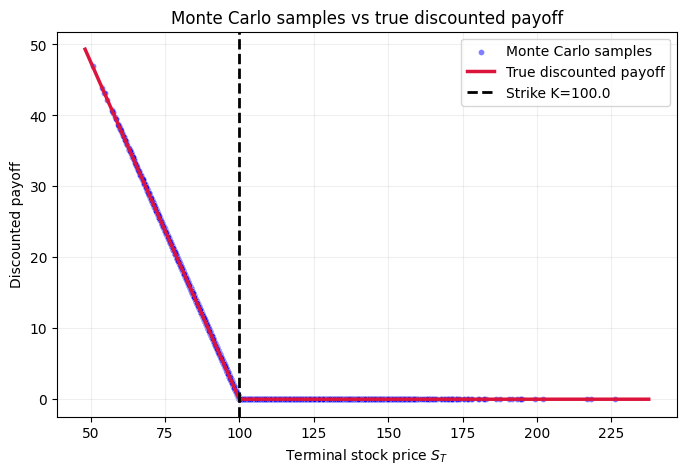

In [21]:
ST = mc_terminal(S0, r, sigma, T, 5000, seed=1)

disc_put_payoff = np.exp(-r*T) * np.maximum(K - ST, 0)

xgrid = np.linspace(ST.min()*0.95, ST.max()*1.05, 500)
ygrid = np.exp(-r*T) * np.maximum(K - xgrid, 0)

plt.figure(figsize=(8,5))

plt.scatter(
    ST,
    disc_put_payoff,
    s=18,
    alpha=0.5,
    color="blue",
    edgecolor="white",
    linewidth=0.3,
    label="Monte Carlo samples",
    zorder=2
)

plt.plot(
    xgrid,
    ygrid,
    color="crimson",
    linewidth=2.5,
    label="True discounted payoff",
    zorder=3
)

plt.axvline(
    K,
    linestyle="--",
    linewidth=2,
    color="black",
    label=f"Strike K={K:.1f}",
    zorder=4
)

plt.xlabel(r"Terminal stock price $S_T$")
plt.ylabel("Discounted payoff")
plt.title("Monte Carlo samples vs true discounted payoff")
plt.grid(True, alpha=0.2)
plt.legend()
plt.show()

### Pricing Asian options with MC

In [22]:
def mc_asian_call(S0: float, K: float, r: float, sigma: float, T: float, n_paths: int, n_steps: int = 50, seed: int = 1) -> Tuple[float, float, float, np.ndarray, np.ndarray]:

    rng = np.random.default_rng(seed)
    dt = T / n_steps

    Z = rng.standard_normal((n_paths, n_steps))
    increments = (r - 0.5*sigma**2)*dt + sigma*np.sqrt(dt)*Z

    log_paths = np.cumsum(increments, axis=1)
    paths = S0 * np.exp(log_paths)

    avg_price = np.mean(paths, axis=1)
    payoff = np.exp(-r*T) * np.maximum(avg_price - K, 0)

    return (*ci(payoff), paths, payoff)

In [23]:
asian_mc, asian_lo, asian_hi, asian_paths, asian_payoffs = mc_asian_call(
    S0, K, r, sigma, T, 10000, n_steps=50
)

print(f"Asian call MC price: {asian_mc:.4f} [{asian_lo:.4f}, {asian_hi:.4f}]")

Asian call MC price: 5.7808 [5.6216, 5.9401]


Reference Asian call price: 5.870916673859169


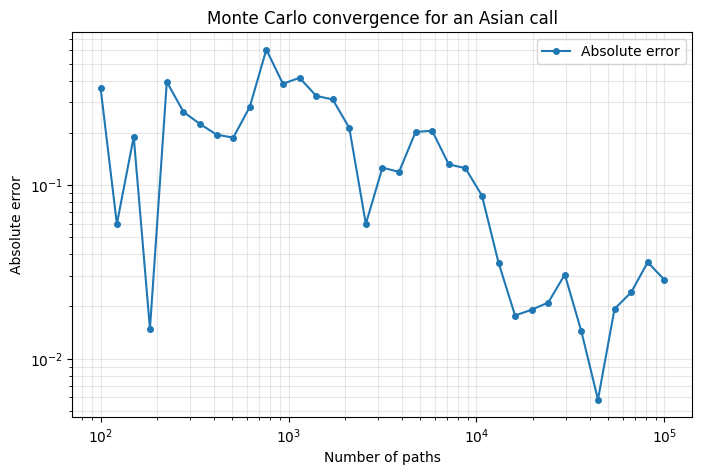

In [24]:
def mc_asian_call_price(S0: float, K: float, r: float, sigma: float, T: float, n_paths: int, n_steps: int = 50, seed: int = 1) -> Tuple[float, np.ndarray]:
    rng = np.random.default_rng(seed)
    dt = T / n_steps
    Z = rng.standard_normal((n_paths, n_steps))
    log_increments = (r - 0.5*sigma**2)*dt + sigma*np.sqrt(dt)*Z
    log_paths = np.cumsum(log_increments, axis=1)
    paths = S0 * np.exp(log_paths)
    avg_price = paths.mean(axis=1)
    payoff = np.exp(-r*T) * np.maximum(avg_price - K, 0)
    return payoff.mean(), payoff

asian_ref, _ = mc_asian_call_price(S0, K, r, sigma, T, n_paths=300000, n_steps=50, seed=123)
print("Reference Asian call price:", asian_ref)

path_grid = np.unique(np.logspace(2, 5, 35, dtype=int))
asian_vals = []

for n in path_grid:
    val, _ = mc_asian_call_price(S0, K, r, sigma, T, n_paths=n, n_steps=50, seed=1)
    asian_vals.append(val)

asian_vals = np.array(asian_vals)
asian_abs_err = np.abs(asian_vals - asian_ref)

plt.figure(figsize=(8,5))
plt.plot(path_grid, asian_abs_err, marker="o", ms=4, lw=1.5, label="Absolute error")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Number of paths")
plt.ylabel("Absolute error")
plt.title("Monte Carlo convergence for an Asian call")
plt.grid(True, alpha=0.3, which="both")
plt.legend()
plt.show()

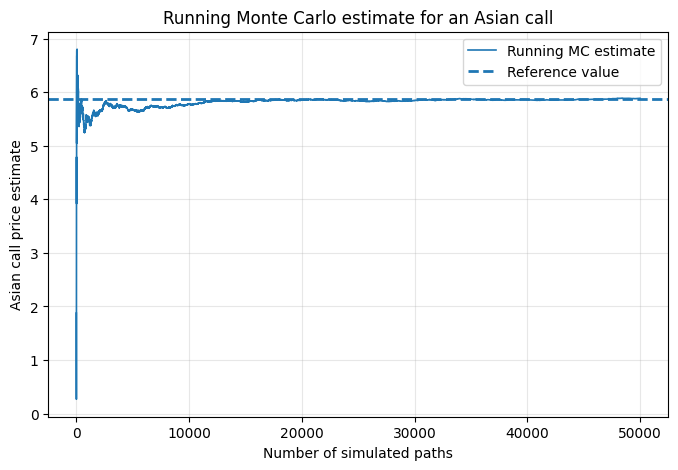

In [26]:
asian_mean, asian_payoffs = mc_asian_call_price(S0, K, r, sigma, T, n_paths=50000, n_steps=50, seed=1)
running_asian = np.cumsum(asian_payoffs) / np.arange(1, len(asian_payoffs)+1)

plt.figure(figsize=(8,5))
plt.plot(running_asian, lw=1.2, label="Running MC estimate")
plt.axhline(asian_ref, linestyle="--", lw=2, label="Reference value")
plt.xlabel("Number of simulated paths")
plt.ylabel("Asian call price estimate")
plt.title("Running Monte Carlo estimate for an Asian call")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

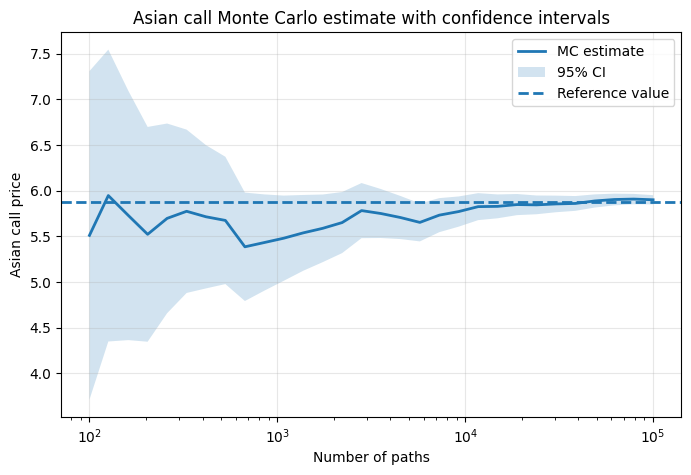

In [27]:
path_grid = np.unique(np.logspace(2, 5, 30, dtype=int))
means, lows, highs = [], [], []

for n in path_grid:
    m, payoffs = mc_asian_call_price(S0, K, r, sigma, T, n_paths=n, n_steps=50, seed=1)
    mean, lo, hi = ci(payoffs)
    means.append(mean); lows.append(lo); highs.append(hi)

means = np.array(means)
lows = np.array(lows)
highs = np.array(highs)

plt.figure(figsize=(8,5))
plt.plot(path_grid, means, lw=2, label="MC estimate")
plt.fill_between(path_grid, lows, highs, alpha=0.2, label="95% CI")
plt.axhline(asian_ref, linestyle="--", lw=2, label="Reference value")
plt.xscale("log")
plt.xlabel("Number of paths")
plt.ylabel("Asian call price")
plt.title("Asian call Monte Carlo estimate with confidence intervals")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

### Variance reduction methods

* Standardizing the normal randoms

* Antithetic random numbers

* Control Variate

#### Standardizing:

We generate $n$ independent std normals

$$\epsilon = \{\epsilon_1, ..., \epsilon_n\} \qquad \epsilon_i \sim \mathcal{N}(0,1) \, iid$$

The sample itself wont have exactly 0 mean and 1 std dev, so we can adjust it with the sample's mean and std dev:

$$\epsilon^* = \frac{\epsilon - \mu}{\sigma}$$

#### Antithetic randoms:

Once epsilon is generated, flip all the random's sign and reuse them:

$$ \epsilon^* =  \{\epsilon_1, ..., \epsilon_n, -\epsilon_1, ..., -\epsilon_n\} $$


### Variance Reduction, Control Variate

The estimator given control variate Y and parameter b is
$$ X^{CV} = X + b(Y - E[Y]) $$


The new estimator is still unbiased:

$$ E[X^{CV}] = E[X] + b(E[Y] - E[E[Y]]) = E[X] $$

Let's see the variance of the new estimator:

$$ Var[X^{CV}] = Var[X] + Var[b*(Y-E[Y])] + 2Cov[X,b(Y - E[Y] )] = Var[X] + b^2Var[Y] + 2bCov[X,Y] $$

Once we decided what control variate Y we will use, we can choose b such that the modified estimator's variance is minimised:

with $ b^*=-\frac{Cov[X,Y]}{Var[Y]} $, the variance of the new estimator will decrease

$$ Var[X^{CV}] = Var[X] - \frac{(Cov[X,Y])^2}{Var[Y]} $$

$$ X^{CV} = X + b(Y - E[Y])\qquad b^*=-\frac{Cov[X,Y]}{Var[Y]} $$

For example for options one can choose forwards as control variate:

$$ X = (S_T - K)^+ $$
$$ Y = S_T - K $$

1, How to determine $b^*$?

* We will simulate n realization of $S_T$
* Evaluate the payoffs of $X$ and $Y$ on each $S^{(i)}_T$
* Use these samples $[X^{(1)}, ...]$, $[Y^{(1)}, ...]$  to estimate $Cov[X,Y]$ and $Var[Y]$

2, How to determine $E[Y]$?

We can only use such contracts as control variates, which have analytic pricing formula. In that case, we can create an analytic pricer for the contract and invoke it's calc_fair_value method.
